In [3]:
#!uv add causal-learn

In [4]:
from aml_working_paper.routing.routing_investigate import build_candidate_windows, select_investigations, validate_investigations
from aml_working_paper.causal.local_sample import prepare_local_windows
from aml_working_paper.causal.ground_truth import get_ground_truth
from aml_working_paper.data.preprocess import preprocess_data
from aml_working_paper.config import INTERIM_DATA_DIR, RAW_DATA_DIR

import pandas as pd

In [5]:
routing_df = pd.read_parquet("{}/routing_df.parquet".format(INTERIM_DATA_DIR))

In [6]:
candidates = pd.read_parquet("{}/candidates.parquet".format(INTERIM_DATA_DIR))

In [7]:
df_aml = pd.read_csv("{}/synthetic_df_aml.csv".format(RAW_DATA_DIR))

In [8]:
train_df, val_df, test_df, train_sequences, val_sequences, test_sequences, scaler = preprocess_data(df_aml)

In [9]:
features = [
    "economic_context",
    "account_exposure",
    "structuring_score",
    "cross_border_ratio",
    "transaction_volume",
]

selected = select_investigations(
    candidates,
    budget=10,
    strategy="uncertainty",
)

local_windows = prepare_local_windows(
    data=val_df,
    selected=selected,
    features=features,
)

print("Number of windows:", len(local_windows))
print(local_windows[0]["data"])


Number of windows: 10
    time  economic_context  account_exposure  structuring_score  \
18    18         -0.985434          0.061948           0.600674   
19    19         -0.712667          0.074647           0.653479   
20    20         -0.030768          0.205329           0.337485   
21    21         -0.709335          0.080911           0.574244   
22    22         -0.344557          0.047874           0.315098   
23    23          0.358036          0.141916           0.765080   
24    24          0.699606          0.081910           0.531208   
25    25          0.790572          0.143995           0.486489   
26    26          0.100495          0.102052           0.900002   
27    27         -0.292715          0.271902           0.145264   

    cross_border_ratio  transaction_volume  
18            0.311376           23.353993  
19            0.340143           29.255242  
20            0.255258           13.256029  
21            0.112332           13.762872  
22            0

In [10]:

for window in local_windows:
    print(
        window["account_id"],
        window["start_time"],
        window["end_time"],
        len(window["data"]),
    )


55.0 18.0 27.0 10
70.0 1.0 10.0 10
12.0 70.0 79.0 10
53.0 83.0 92.0 10
33.0 74.0 83.0 10
33.0 13.0 22.0 10
30.0 81.0 90.0 10
40.0 0.0 9.0 10
15.0 88.0 97.0 10
44.0 62.0 71.0 10


In [11]:
print(local_windows[0]["data"].columns.tolist())

['time', 'economic_context', 'account_exposure', 'structuring_score', 'cross_border_ratio', 'transaction_volume']


In [12]:
current_edges, temporal_edges = get_ground_truth()

print("Current edges:", len(current_edges))
print("Temporal edges:", len(temporal_edges))

Current edges: 8
Temporal edges: 2


In [13]:
from aml_working_paper.causal.discovery_data import (
    prepare_discovery_data,
)

discovery_data = prepare_discovery_data(local_windows)

print(discovery_data.shape)
print(discovery_data.head())

(100, 8)
   time  economic_context  account_exposure  structuring_score  \
0    18         -0.985434          0.061948           0.600674   
1    19         -0.712667          0.074647           0.653479   
2    20         -0.030768          0.205329           0.337485   
3    21         -0.709335          0.080911           0.574244   
4    22         -0.344557          0.047874           0.315098   

   cross_border_ratio  transaction_volume  window_id  account_id  
0            0.311376           23.353993          0          55  
1            0.340143           29.255242          0          55  
2            0.255258           13.256029          0          55  
3            0.112332           13.762872          0          55  
4            0.187702           18.888078          0          55  


In [14]:
features = [
    "economic_context",
    "account_exposure",
    "structuring_score",
    "cross_border_ratio",
    "transaction_volume",
]

# Check missing values
print(discovery_data[features].isna().sum())

# Check variability
print(discovery_data[features].nunique())

# Check observations per window
print(discovery_data.groupby("window_id").size())

economic_context      0
account_exposure      0
structuring_score     0
cross_border_ratio    0
transaction_volume    0
dtype: int64
economic_context       62
account_exposure      100
structuring_score     100
cross_border_ratio    100
transaction_volume    100
dtype: int64
window_id
0    10
1    10
2    10
3    10
4    10
5    10
6    10
7    10
8    10
9    10
dtype: int64


In [15]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Select the variables
x = discovery_data["economic_context"].to_numpy()
y = discovery_data["cross_border_ratio"].to_numpy()
z = discovery_data[["account_exposure"]].to_numpy()

# Correlation without controlling for anything
correlation = np.corrcoef(x, y)[0, 1]

# Explain X using Z
model_x = LinearRegression().fit(z, x)
residual_x = x - model_x.predict(z)

# Explain Y using Z
model_y = LinearRegression().fit(z, y)
residual_y = y - model_y.predict(z)

# Correlation after controlling linearly for Z
partial_correlation = np.corrcoef(
    residual_x,
    residual_y,
)[0, 1]

print("Correlation:", round(correlation, 3))
print("Partial correlation:", round(partial_correlation, 3))

Correlation: 0.145
Partial correlation: 0.164


In [16]:

import numpy as np
from sklearn.linear_model import LinearRegression


def compare_correlations(data):

    x = data["economic_context"].to_numpy()
    y = data["cross_border_ratio"].to_numpy()
    z = data[["account_exposure"]].to_numpy()

    # Original correlation
    correlation = np.corrcoef(x, y)[0, 1]

    # Remove the linear contribution of Z
    residual_x = x - LinearRegression().fit(z, x).predict(z)
    residual_y = y - LinearRegression().fit(z, y).predict(z)

    # Correlation after controlling for Z
    partial = np.corrcoef(residual_x, residual_y)[0, 1]

    return correlation, partial


# Full validation data
full_corr, full_partial = compare_correlations(val_df)

# Selected investigation windows
selected_corr, selected_partial = compare_correlations(
    discovery_data
)

print("Full validation:")
print(round(full_corr, 3), round(full_partial, 3))

print("Selected windows:")
print(round(selected_corr, 3), round(selected_partial, 3))


Full validation:
0.088 -0.029
Selected windows:
0.145 0.164


In [17]:
from aml_working_paper.causal.discovery import discover_pc

features = [
    "economic_context",
    "account_exposure",
    "structuring_score",
    "cross_border_ratio",
    "transaction_volume",
]

graph = discover_pc(
    discovery_data,
    features,
)

print(graph.G.get_graph_edges())

[<causallearn.graph.Edge.Edge object at 0x745dbb306ad0>, <causallearn.graph.Edge.Edge object at 0x745deeca0250>, <causallearn.graph.Edge.Edge object at 0x745deeca14d0>, <causallearn.graph.Edge.Edge object at 0x745daf691cd0>]


In [18]:
for edge in graph.G.get_graph_edges():
    print(edge)

X1 --- X2
X1 --> X5
X3 --- X4
X3 --> X5


In [19]:
graph = discover_pc(discovery_data, features)

In [20]:

# Map generic node names to our variables
names = {
    "X1": "economic_context",
    "X2": "account_exposure",
    "X3": "structuring_score",
    "X4": "cross_border_ratio",
    "X5": "transaction_volume",
}

# Print edges using the original variable names
for edge in graph.G.get_graph_edges():

    edge_text = str(edge)

    for old_name, new_name in names.items():
        edge_text = edge_text.replace(old_name, new_name)

    print(edge_text)


economic_context --- account_exposure
economic_context --> transaction_volume
structuring_score --- cross_border_ratio
structuring_score --> transaction_volume


In [21]:
random_selected = select_investigations(
    candidates,
    budget=10,
    strategy="random",
)

random_windows = prepare_local_windows(
    data=val_df,
    selected=random_selected,
    features=features,
)

random_data = prepare_discovery_data(random_windows)

random_graph = discover_pc(random_data, features)

for edge in random_graph.G.get_graph_edges():
    edge_text = str(edge)

    for old_name, new_name in names.items():
        edge_text = edge_text.replace(old_name, new_name)

    print(edge_text)

economic_context --- account_exposure
economic_context --> transaction_volume
structuring_score --- cross_border_ratio
structuring_score --> transaction_volume


In [22]:
strategies = [
    "uncertainty",
    "surprise",
    "combined",
    "random",
]

results = {}

for strategy in strategies:

    # Select investigation windows
    selected = select_investigations(
        candidates,
        budget=10,
        strategy=strategy,
    )

    # Recover original observations
    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    # Prepare discovery data
    data = prepare_discovery_data(windows)

    # Run PC
    graph = discover_pc(data, features)

    # Translate edges to original variable names
    edges = []

    for edge in graph.G.get_graph_edges():

        edge_text = str(edge)

        for old_name, new_name in names.items():
            edge_text = edge_text.replace(old_name, new_name)

        edges.append(edge_text)

    results[strategy] = edges

    print(f"\nStrategy: {strategy}")
    print(f"Number of edges: {len(edges)}")

    for edge in edges:
        print(edge)


Strategy: uncertainty
Number of edges: 4
economic_context --- account_exposure
economic_context --> transaction_volume
structuring_score --- cross_border_ratio
structuring_score --> transaction_volume

Strategy: surprise
Number of edges: 4
account_exposure --> economic_context
structuring_score --> economic_context
structuring_score --- cross_border_ratio
structuring_score --- transaction_volume

Strategy: combined
Number of edges: 4
account_exposure --> economic_context
transaction_volume --> economic_context
structuring_score --- cross_border_ratio
structuring_score --- transaction_volume

Strategy: random
Number of edges: 4
economic_context --- account_exposure
economic_context --> transaction_volume
structuring_score --- cross_border_ratio
structuring_score --> transaction_volume


In [23]:
true_edges = [
    ("economic_context", "account_exposure"),
    ("economic_context", "transaction_volume"),
    ("account_exposure", "cross_border_ratio"),
    ("structuring_score", "transaction_volume"),
]

In [24]:

def evaluate_skeleton(discovered, true_edges):
    """Compare discovered connections, ignoring direction."""

    # True connections, without direction
    truth = {frozenset(edge) for edge in true_edges}

    # Discovered connections, without direction
    predicted = set()

    for edge in discovered:

        if " --> " in edge:
            nodes = edge.split(" --> ")
        elif " --- " in edge:
            nodes = edge.split(" --- ")
        elif " <-- " in edge:
            nodes = edge.split(" <-- ")
        else:
            raise ValueError(f"Unknown edge format: {edge}")

        predicted.add(frozenset(nodes))

    # Correctly discovered connections
    tp = len(predicted & truth)

    # Additional and missing connections
    fp = len(predicted - truth)
    fn = len(truth - predicted)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0
    )

    return precision, recall, f1


In [25]:
for strategy, edges in results.items():

    precision, recall, f1 = evaluate_skeleton(
        edges,
        true_edges,
    )

    print(
        strategy,
        round(precision, 3),
        round(recall, 3),
        round(f1, 3),
    )

uncertainty 0.75 0.75 0.75
surprise 0.5 0.5 0.5
combined 0.75 0.75 0.75
random 0.75 0.75 0.75


In [26]:
from aml_working_paper.causal.discovery import discover_fci

fci_graph = discover_fci(discovery_data, features)

for edge in fci_graph.get_graph_edges():
    print(edge)

X1 o-o X2
X1 o-> X5
X3 o-o X4
X3 o-> X5


In [27]:
for edge in fci_graph.get_graph_edges():

    edge_text = str(edge)

    for old_name, new_name in names.items():
        edge_text = edge_text.replace(old_name, new_name)

    print(edge_text)

economic_context o-o account_exposure
economic_context o-> transaction_volume
structuring_score o-o cross_border_ratio
structuring_score o-> transaction_volume


In [28]:
fci_results = {}

for strategy in strategies:

    selected = select_investigations(
        candidates,
        budget=10,
        strategy=strategy,
    )

    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    data = prepare_discovery_data(windows)

    graph = discover_fci(data, features)

    edges = []

    for edge in graph.get_graph_edges():

        edge_text = str(edge)

        for old_name, new_name in names.items():
            edge_text = edge_text.replace(old_name, new_name)

        edges.append(edge_text)

    fci_results[strategy] = edges

    print(f"\nStrategy: {strategy}")

    for edge in edges:
        print(edge)


Strategy: uncertainty
economic_context o-o account_exposure
economic_context o-> transaction_volume
structuring_score o-o cross_border_ratio
structuring_score o-> transaction_volume

Strategy: surprise
account_exposure o-> economic_context
economic_context <-> structuring_score
cross_border_ratio o-> structuring_score
transaction_volume o-> structuring_score

Strategy: combined
account_exposure o-> economic_context
economic_context <-> transaction_volume
structuring_score o-o cross_border_ratio
structuring_score o-> transaction_volume

Strategy: random
economic_context o-o account_exposure
economic_context o-> transaction_volume
structuring_score o-o cross_border_ratio
structuring_score o-> transaction_volume


In [29]:
import pandas as pd

from aml_working_paper.causal.evaluation import evaluate_skeleton

summary = []

for method, method_results in [
    ("PC", results),
    ("FCI", fci_results),
]:

    for strategy, edges in method_results.items():

        metrics = evaluate_skeleton(edges)

        summary.append({
            "method": method,
            "strategy": strategy,
            **metrics,
        })

evaluation_df = pd.DataFrame(summary)

print(evaluation_df)

  method     strategy  TP  FP  FN  precision  recall    f1
0     PC  uncertainty   3   1   1       0.75    0.75  0.75
1     PC     surprise   2   2   2       0.50    0.50  0.50
2     PC     combined   3   1   1       0.75    0.75  0.75
3     PC       random   3   1   1       0.75    0.75  0.75
4    FCI  uncertainty   3   1   1       0.75    0.75  0.75
5    FCI     surprise   2   2   2       0.50    0.50  0.50
6    FCI     combined   3   1   1       0.75    0.75  0.75
7    FCI       random   3   1   1       0.75    0.75  0.75


In [30]:

import pandas as pd

from aml_working_paper.causal.evaluation import evaluate_skeleton

random_results = []

# Repeat random selection with 50 different seeds
for seed in range(42, 92):

    # Select 10 random investigation windows
    selected = select_investigations(
        candidates,
        budget=10,
        strategy="random",
        random_state=seed,
    )

    # Recover the original observations
    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    # Combine the selected observations
    data = prepare_discovery_data(windows)

    # Run PC
    graph = discover_pc(data, features)

    # Get discovered connections
    edges = []

    for edge in graph.G.get_graph_edges():

        edge_text = str(edge)

        for old_name, new_name in names.items():
            edge_text = edge_text.replace(old_name, new_name)

        edges.append(edge_text)

    # Evaluate the discovered skeleton
    metrics = evaluate_skeleton(edges)

    random_results.append({
        "seed": seed,
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
    })

random_df = pd.DataFrame(random_results)

print(random_df.head())


   seed  precision  recall        f1
0    42       0.75    0.75  0.750000
1    43       0.50    0.50  0.500000
2    44       0.75    0.75  0.750000
3    45       0.60    0.75  0.666667
4    46       0.75    0.75  0.750000


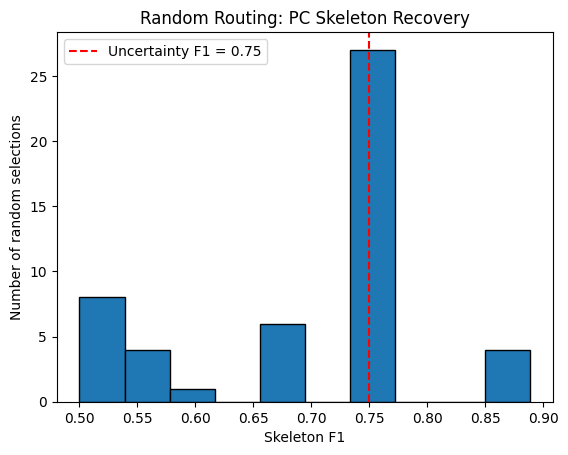

In [31]:
import matplotlib.pyplot as plt

plt.hist(
    random_df["f1"],
    bins=10,
    edgecolor="black",
)

plt.axvline(
    0.75,
    color="red",
    linestyle="--",
    label="Uncertainty F1 = 0.75",
)

plt.xlabel("Skeleton F1")
plt.ylabel("Number of random selections")
plt.title("Random Routing: PC Skeleton Recovery")
plt.legend()
plt.show()

In [32]:
uncertainty_f1 = 0.75

equal_or_better = (
    random_df["f1"] >= uncertainty_f1
).mean()

print("Random mean F1:", random_df["f1"].mean())
print("Random standard deviation:", random_df["f1"].std())

print(
    "Fraction of random selections >= uncertainty:",
    equal_or_better,
)

Random mean F1: 0.6938253968253969
Random standard deviation: 0.11167544801797749
Fraction of random selections >= uncertainty: 0.62


In [33]:
print(random_df["f1"].describe())

print(
    (random_df["f1"] >= 0.75).mean()
)

count    50.000000
mean      0.693825
std       0.111675
min       0.500000
25%       0.616667
50%       0.750000
75%       0.750000
max       0.888889
Name: f1, dtype: float64
0.62


In [34]:

import pandas as pd

# Results from our previous PC evaluation
pc_scores = evaluation_df[
    evaluation_df["method"] == "PC"
].set_index("strategy")

# Comparison table
comparison = pd.DataFrame({
    "strategy": [
        "uncertainty",
        "surprise",
        "combined",
        "random",
    ],
    "mean_f1": [
        pc_scores.loc["uncertainty", "f1"],
        pc_scores.loc["surprise", "f1"],
        pc_scores.loc["combined", "f1"],
        random_df["f1"].mean(),
    ],
    "std_f1": [
        0.0,
        0.0,
        0.0,
        random_df["f1"].std(),
    ],
})

print(comparison.round(3))


      strategy  mean_f1  std_f1
0  uncertainty    0.750   0.000
1     surprise    0.500   0.000
2     combined    0.750   0.000
3       random    0.694   0.112


In [35]:
for strategy in strategies:

    selected = select_investigations(
        candidates,
        budget=10,
        strategy=strategy,
    )

    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    data = prepare_discovery_data(windows)

    # Variability within each selected window
    variability = (
        data.groupby("window_id")[features]
        .std()
        .mean()
    )

    print(f"\n{strategy}")
    print(variability.round(3))


uncertainty
economic_context      0.649
account_exposure      0.095
structuring_score     0.136
cross_border_ratio    0.082
transaction_volume    6.459
dtype: float64

surprise
economic_context      0.779
account_exposure      0.104
structuring_score     0.156
cross_border_ratio    0.134
transaction_volume    8.113
dtype: float64

combined
economic_context      0.707
account_exposure      0.111
structuring_score     0.120
cross_border_ratio    0.096
transaction_volume    8.250
dtype: float64

random
economic_context      0.619
account_exposure      0.094
structuring_score     0.181
cross_border_ratio    0.120
transaction_volume    7.478
dtype: float64


In [36]:
from aml_working_paper.causal.evaluation import (
    summarize_causal_results,
)

summary = summarize_causal_results(
    evaluation_df,
    random_df,
)

print(summary)

{'uncertainty_f1': 0.75, 'random_mean_f1': 0.6938253968253969, 'random_std_f1': 0.11167544801797749, 'random_fraction_ge_uncertainty': 0.62, 'random_repetitions': 50}
